In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from joblib import Parallel, delayed
from scipy.signal import savgol_filter as sgf
from scipy.optimize import curve_fit
from sklearn import linear_model
from sklearn import metrics

# changing matplotlib font style so that pdf's saved from this notebook can be opened in Adobe illustrator
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.sans-serif'] = "Arial"
mpl.rcParams['font.family'] = "sans-serif"
mpl.rcParams['font.size'] = 18


In [16]:
print(np.__version__)
print(pd.__version__)
print(mpl.__version__)
import joblib
print(joblib.__version__)
import scipy
print(scipy.__version__)
import sklearn
print(sklearn.__version__)

1.18.1
1.0.1
3.1.3
0.14.1
1.4.1
0.22.1


In [2]:
'''
Functions used in this notebook:
flatten (helper function)
fit_w_diffsx : deconvolution algorithm
scat_subtract : scattering subtraction using curve_fit, used for reference spectra

'''
# handy function that turns lists of lists into a single list
def flatten(list1):
    return [item for sublist in list1 for item in sublist]

# deconvolution algorithm
def fit_w_diffsx(absorption, wavelengths, speclist):
    '''
    parameters: 
    absorption - optical density values as pandas Series.
    wavelengths - wavelengths as 1-D array or list. Every wavelength must have an associated absorption value, otherwise this will return a key error
    speclist - pandas dataframe containing all reference spectra and functions used to deconvolute the 
    
    outputs:
    lscv1.coef_ : numpy array of model coefficients - these correspond to relative concentration/spectral intensity
    score: scalar, R2 value of the overall fit.
    lscv1 : LassoCV object containing the fitted function.
    '''
    lscv1 = linear_model.LassoCV(positive = True,cv = 4, max_iter = 10000)
    # create LassoCV instance
    wavelengths  = list(wavelengths)
    # convert wavelengths to list format
    abso = np.hstack((absorption[wavelengths],20*sgf(absorption[wavelengths[5:]],21,4,deriv=1),100*sgf(absorption[wavelengths[10:]],21,4,deriv=2)))
    # calculate smoothed first and second derivatives of absorption values, rescale values and convert to single array
    specs = np.vstack((speclist[wavelengths].values.transpose(),20*sgf(speclist[wavelengths[5:]].values,21,4,deriv=1).transpose(),100*sgf(speclist[wavelengths[10:]].values,21,4,deriv=2).transpose()))
    # calculate first and second derivatives of reference spectra, convert to numpy array and stack into matrix
    lscv1.fit(specs,abso)
    # fit LassoCV function (cross-validation happens internally)
    return lscv1.coef_, metrics.r2_score(abso,lscv1.predict(specs)), lscv1

# scattering subtraction for reference samples
def scat_subtract(array,waves,num2,num3):
    # subtracts a power law scattering background a*x^b from the array. the power law is fit in the region of num2:num3
    # This means there should be no absorption feature from the sample besides scattering in that region
    def fit_func(x,b,a):
        # helper function that defines a line function
        return a+x*b
    
    param_bounds = ([-4,-np.inf],[0,np.inf])
    # the scattering factor b should be no smaller than -4, and no larger than 0 based on physical constraints.
    log = np.log10(np.array(array))
    logw = np.log10(np.array(waves))
    # turn the arrays into logs to fit the power law
    #print(log[num2:num3])
    #print(logw[num2:num3])
    paramslog = curve_fit(fit_func,logw[num2:num3],log[num2:num3],p0 = [-2,1], bounds = param_bounds)
    # fits the parameters on a log scale
    paramslin = [[paramslog[0][0],10**paramslog[0][1]],
                 [np.sqrt(paramslog[1][0][0]),0.434*np.sqrt(paramslog[1][1][1])/paramslog[0][1]]]
    # extracts linear parameters in linear scale from the log plot, including errors (paramslin[1])
    def scat_func (x,b,a):
        return a*x**b
    scatter = scat_func(np.array(waves),paramslin[0][0],paramslin[0][1])
    # creates scatter function based on the parameters extracted
    # returns the initial array minus the calculated scatter function
    return array-scatter

In [3]:
# read data files
Synth = pd.read_csv('CsPbBr_synthesis.csv', index_col = 0)
Trans = pd.read_csv('CsPbBr_transformations.csv', index_col = 0)


In [4]:
Combi = pd.concat([Synth,Trans])
# create combined file with all spectra
print(list(Combi.columns))

['250', '251', '252', '253', '254', '255', '256', '257', '258', '259', '260', '261', '262', '263', '264', '265', '266', '267', '268', '269', '270', '271', '272', '273', '274', '275', '276', '277', '278', '279', '280', '281', '282', '283', '284', '285', '286', '287', '288', '289', '290', '291', '292', '293', '294', '295', '296', '297', '298', '299', '300', '301', '302', '303', '304', '305', '306', '307', '308', '309', '310', '311', '312', '313', '314', '315', '316', '317', '318', '319', '320', '321', '322', '323', '324', '325', '326', '327', '328', '329', '330', '331', '332', '333', '334', '335', '336', '337', '338', '339', '340', '341', '342', '343', '344', '345', '346', '347', '348', '349', '350', '351', '352', '353', '354', '355', '356', '357', '358', '359', '360', '361', '362', '363', '364', '365', '366', '367', '368', '369', '370', '371', '372', '373', '374', '375', '376', '377', '378', '379', '380', '381', '382', '383', '384', '385', '386', '387', '388', '389', '390', '391', '392'

In [5]:
reference_names = ['p1G2','p1C11','p1D9','p14A9','p14G5','p14B1','p14E4','p9A1','p2D5','p4D11','p15E2','p20B5']
# names of reference spectra
abso_waves = [str(i) for i in range(300,701,1)]
ref_scales = [1,0.65,0.75,0.5,0.5,0.5,0.75,1.2,3.1,0.7,1.3,5]
# scales of reference spectra to approximately 0.5 O.D. at 330 nm for perovskite species, slightly higher for others
refs = Combi.loc[reference_names, abso_waves]
# selects references with wavelengths
refs = refs.multiply(ref_scales,axis=0)
# scales references
refs = refs.reindex(['p15E2', 'p9A1', 'p2D5','p14E4','p14G5','p14B1','p14A9','p1D9','p1C11', 'p4D11','p1G2','p20B5'])
# changes index to line up with labels
labels = ['PbBr3-','Cs4PbBr6','CsPb2Br5','PbBr2','1 ML','1 ML_2','2 ML','2 ML_2','3 ML','4 ML','CsPbBr3','bg']
ref_dict = {list(refs.index)[i] : labels[i] for i in range(len(labels))}
refs = refs.rename(index = ref_dict)
# rename dataframe so that the labels are the indices
refs = refs.apply(scat_subtract, axis = 1, args = (np.arange(300,701,1),-150,-1))
# applies scattering subtraction (single exponent confined between lambda**0 and lambda**-4), calculated between 550 and 700 nm
# add scattering lines
refs.loc['s1'] = np.arange(300,701,1.0)**(0)/300**0
refs.loc['s2'] = np.arange(300,701,1.0)**(-1)/300**-1
refs.loc['s3'] = np.arange(300,701,1.0)**(-2)/300**-2
refs.loc['s4'] = np.arange(300,701,1.0)**(-3)/300**-3
refs.loc['s5'] = np.arange(300,701,1.0)**(-4)/300**-4


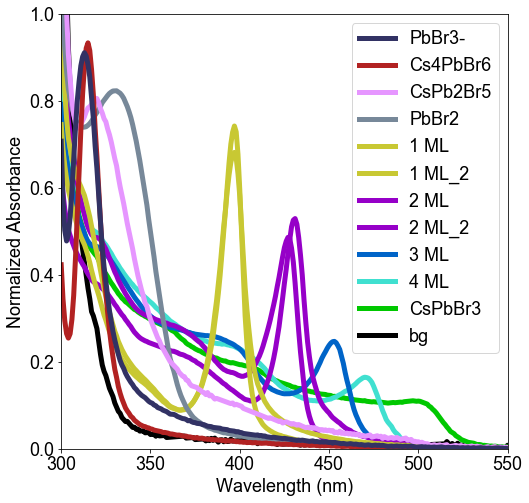

In [6]:
labels2 = ['PbBr3-','Cs4PbBr6','CsPb2Br5','PbBr2','1 ML','1 ML_2','2 ML','2 ML_2','3 ML','4 ML','CsPbBr3','bg','s1','s2', 's3','s4', 's5'] 
# colors used for each sample
facecolor2 = [(50,50,100),(178,34,34),(230,150,255),(119,136,153),(200,200,51),(200,200,51),(150,0,200),(150,0,200),(0,100,200),(64,224,208),(0,200,0),(0,0,0),(178,34,34),(240,230,140),(255,127,80),(255,165,0),(154,205,50)]
facecolor2 = [(color[0]/255,color[1]/255,color[2]/255) for color in facecolor2]
facecolor = [(50,50,100),(178,34,34),(230,150,255),(119,136,153),(200,200,51),(150,0,200),(0,100,200),(64,224,208),(0,200,0),(0,0,0),(178,34,34),(240,230,140),(255,127,80),(255,165,0),(154,205,50)]
facecolor = [(color[0]/255,color[1]/255,color[2]/255) for color in facecolor]
n = 0
plt.figure(figsize = (8,8))
for i in labels:
    plt.plot(range(300,701,1),refs.loc[i,abso_waves],label = i,color = facecolor2[n],linewidth = 5,zorder = 1/(n+1))
    n += 1
plt.legend()
plt.ylim(0,1)    
plt.xlim(300,550)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Normalized Absorbance')
#plt.savefig('Figure 3C.pdf', format = 'pdf') # uncomment beginning if you want to save the figure

plt.show()

In [7]:
'''
Uses joblib to paralellize the fit_w_diffsx function to 
deconvolute the entire dataset into the different spectra defined in refs
should take ~1 minute with paralellization on a modern computer, ~4 without. There isn't much overhead on these.
This cell can be skipped - the results of this analysis are already written into the data files.
'''
#import time
#t1 = time.time()
results = Parallel(n_jobs = -1) (delayed(fit_w_diffsx)(Combi.iloc[i,:],abso_waves,refs) for i in range(len(Combi)))
#t2 = time.time()
#print('Execution time in seconds: '  + str(t2-t1))

Execution time in seconds: 54.97904586791992


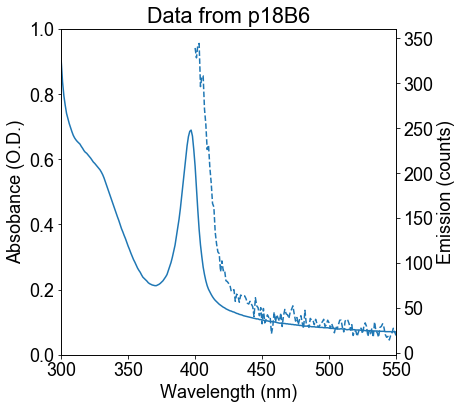

In [8]:
# Making a plot that displays any particular absorption and emission spectrum
test = Combi.iloc[1796,:]
# taking data from entry # 400
plt.figure(figsize = (6,6))
ax = plt.gca()
# plotting absorption
ax.plot(range(300,701,1),test[abso_waves])
ax.set_ylabel('Absobance (O.D.)')
ax.set_xlim(300,550)
ax.set_ylim(0,1)
ax2 = ax.twinx()
# creating separate axis
em_waves = ['e' + str(i) + '.0' for i in range(400,551,1)]
#plotting emission
ax2.plot(range(400,551,1),test[em_waves],linestyle = '--')
ax2.set_ylabel('Emission (counts)')
ax.set_xlabel('Wavelength (nm)')
plt.title('Data from ' + str(test.name))
plt.show()

PbBr3-              0
Cs4PbBr6            0
CsPb2Br5    0.0567104
PbBr2        0.227348
1 ML          0.59787
1 ML_2       0.131672
2 ML                0
2 ML_2              0
3 ML                0
4 ML                0
CsPbBr3             0
Name: p18B6, dtype: object
0.9879948612977892


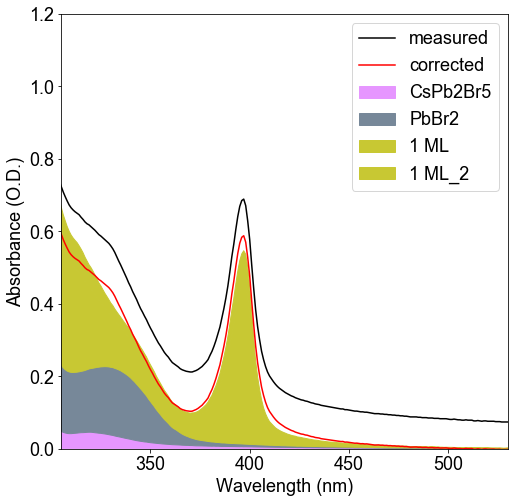

In [9]:
# Demonstrating Deconvolution on the previous measure
# Define figure properties
mpl.rcParams.update({'font.size': 18})
plt.figure(figsize = (8,8))

# Define x and y values for absorption, plot them as measured
xs = pd.RangeIndex(start = 300,stop=701,step=1)
ys = test[abso_waves]
plt.plot(xs,ys,color = 'k',label = 'measured')

# get coefficients, except for the last one (which is bg)
coeffs = test[labels[:-1]]
# list of scattering + background values
scatters = ['bg','s1','s2','s3','s4','s5']
# get scattering coefficients
scat_coeffs = test[scatters]

# calculated total scattering
ys_scat = np.zeros(len(ys))

for i in range(len(scat_coeffs)):
    # add each scattering coefficient * the absorbance values
    ys_scat += scat_coeffs[i]*refs.loc[scatters[i],:]

plt.plot(xs,ys-ys_scat,color = 'r',label = 'corrected')
# plot absorbance - calculated total scattering
print(coeffs)
print(test['Deconvolution R^2'])

# calculated absorption values 
nums = np.zeros(len(xs))
# go through each species
for i in range(len(coeffs)):
    # only add if species has significant contribution
    if coeffs[i]>0.03:
        # fill area between nums and nums with the absorption of the species added

        plt.fill_between(xs,nums,nums+coeffs[i]*refs.iloc[i,:],label = coeffs.index[i],color = facecolor2[i])
    
    # add the absorption of the species to nums
    nums+=coeffs[i]*refs.iloc[i,:]
    
# mark up plot so it's readable
plt.legend()
plt.xlim(305,530)
plt.xlabel('Wavelength (nm)')
plt.ylim(0,1.2)
plt.ylabel('Absorbance (O.D.)')
#plt.savefig('Figure 3D.pdf', format = 'pdf') # uncomment beginning if you want to save the figure
plt.show()

In [10]:
'''
function that creates lists of xy arrays that define a slice of a given size depending on a list of ratios passed.
this allows us to create pie charts as objects in a scatter plot by constructing them slice by slice
idea for implementation comes from: https://stackoverflow.com/questions/56337732/how-to-plot-scatter-pie-chart-using-matplotlib
'''
def ratios_to_arcs(rat_array):
    xy_list = []
    for j in range(len(rat_array)):
        rat_sum_array = [0]
        xy_list.append([])
        for i in range(len(rat_array[j])):
            rat_sum_array.append(rat_sum_array[i] + rat_array[j][i])
            x = [0] + np.cos(np.linspace(2*np.pi*rat_sum_array[i],
                                         2 * np.pi * rat_sum_array[i+1],
                                         100)).tolist()
            y = [0] + np.sin(np.linspace(2*np.pi*rat_sum_array[i],
                                         2 * np.pi * rat_sum_array[i+1],
                                         100)).tolist()
            xy_list[j].append(np.column_stack([x,y]))
    return xy_list

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:20: RuntimeWarning: invalid value encountered in true_divide
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:29: MatplotlibDeprecationWarning: Passing vertices as `(verts, 0)` is deprecated since Matplotlib 3.0, and support for it will be removed in 3.2.  Directly pass `verts` instead.


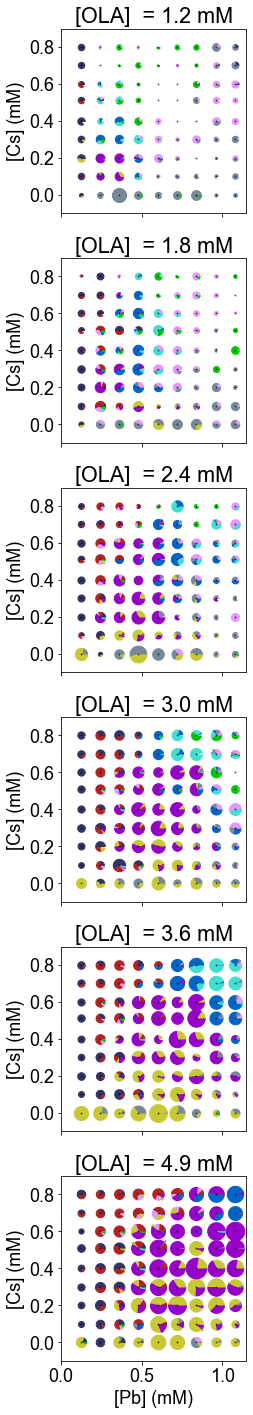

In [11]:
# Creating the array of pie-charts figure
# setting up the figure
fig,ax = plt.subplots(6,1,sharex=True,sharey=True,figsize=(4,20))
mpl.rcParams.update({'font.size': 18})

# restricting the data to what goes into the figure
sub_mega_csubs = Synth[(Synth['OA'] == 60) & (Synth['Br'] == 60) & (Synth['Temp'] == 30) & (Synth['Pb'].isin([20,40,60,80,100,120,140,160,180])) & (Synth['Cs'].isin([0,10,20,30,40,51,60,70,80]))& (Synth['Dodecane']>0)]
sub_mega_csubs = sub_mega_csubs.groupby(['OLA','Pb','OA','Cs']).mean().reset_index()

# define oleylamine concentrations
OLA_divs = [20,30,40,50,60,80]

# iterate through the different OLA concentrations
for j in range(len(OLA_divs)):
    # restrict data to OLA concentration
    sub_data = sub_mega_csubs.loc[sub_mega_csubs['OLA'] == OLA_divs[j],:]
    
    
    vals = [line[1][labels[:-1]].values for line in sub_data.iterrows()] # getting values from dataframe
    ratios = [val/sum(val) for val in vals] # converting values to ratios
    xys = ratios_to_arcs(ratios) # converting ratios to slices to draw
    
    for k in range(len(ratios)): # iterating through the ratios
        for l in range(len(ratios[0])): # iterating through the species
            if not vals[k][l-11] <0.03: # only showing those with major contributions
                # plot the slices of the pie charts, at each individual Pb and Cs location
                # sum of values is used to scale the slices so that the scale of the pie chart corresponds to the amount of species
                # color as expected previously
                ax[j].scatter(sub_data.iloc[k,1]*0.003/0.5,sub_data.iloc[k,3]*0.005/0.5,s = 100*sum(vals[k]),marker = [xys[k][l],0],facecolor = facecolor2[l])


    ax[j].scatter(sub_data['Pb']*0.003/0.5, sub_data['Cs']*0.005/0.5,color = 'k',s=1,alpha = 0.5)
    # add dots to the middle of pie charts (good for checking that the Cs & Pb values are correct)
    
    # add explanatory stuff
    ax[j].set_title('[OLA]  = ' + str(round(OLA_divs[j]*0.0304/0.5,1)) + ' mM')
    ax[j].set_ylabel('[Cs] (mM)')
    ax[j].set_xlim(0.0,1.15)

ax[-1].set_xlabel('[Pb] (mM)')
fig.tight_layout()
#plt.savefig('Figure S 3_7.pdf', format = 'pdf') # uncomment beginning if you want to save the figure
plt.show()

In [12]:
# Making the colors for the map:
from matplotlib.colors import ListedColormap
from matplotlib import cm
# importing colormap help 

def make_cmap(R,G,B,N = 256):
    # takes an R,G,B value and creates a colormap going from a lighter shade of that color to the color defined
    vals = np.ones((N,4))
    vals[:,0] = np.linspace(1-(1-R/N)/2,R/N,N)
    vals[:,1] = np.linspace(1-(1-G/N)/2,G/N,N)
    vals[:,2] = np.linspace(1-(1-B/N)/2,B/N,N)
    return ListedColormap(vals)

# defined colormaps, mostly correlate with facecolor
dpurple = make_cmap(50,50,100)
turquoise = make_cmap(64,224,208)
yellow = make_cmap(200,200,51)
slate = make_cmap(169,176,193)
dgrey = make_cmap(70,70,70)
black = make_cmap(0,0,0)
cyan = make_cmap(0,200,200)
blue = make_cmap(0,100,200)
green = make_cmap(0,200,0)
purple = make_cmap(170,30,240)
pink = make_cmap(230,150,255)
red = make_cmap(230,30,30)

In [13]:
from scipy.interpolate import Rbf
# importing the Radial Basis function interpolation

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:58: UserWarning: No contour levels were found within the data range.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:58: UserWarning: The following kwargs were not used by contour: 'color'
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:59: UserWarning: No contour levels were found within the data range.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:59: UserWarning: The following kwargs were not used by contour: 'color'
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:60: UserWarning: The following kwargs were not used by contour: 'color'
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:61: UserWarning: The following kwargs were not used by contour: 'color'
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:62: UserWarning: The following kwargs were not used by contour: 'color'
C:\ProgramData\Anaconda3\lib\site-packages\ipyk

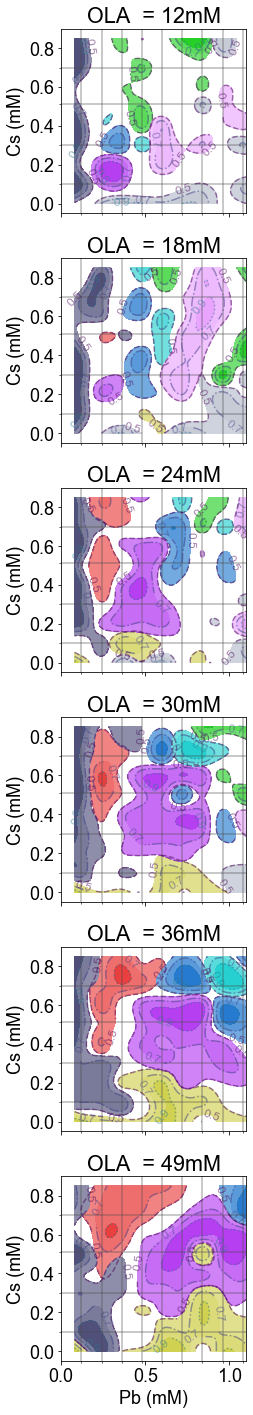

In [18]:
# Creating the map figure
mpl.rcParams.update({'font.size': 18})
fig,ax = plt.subplots(6,1,sharex=True,sharey=True,figsize=(4,20))
# setting up the figure

sub_mega_csubs = Synth[(Synth['OA'] == 60) & (Synth['Br'] == 60) & (Synth['Temp'] == 30) & (Synth['Pb'].isin([20,40,60,80,100,120,140,160,180])) & (Synth['Cs'].isin([0,10,20,30,40,51,60,70,80]))& (Synth['Dodecane']>0)]
sub_mega_csubs = sub_mega_csubs.groupby(['OLA', 'Pb', 'Cs']).mean().reset_index()
# Restricting data to that shown in the figure

# Fitting one Rbf interpolator to each fraction as a function of Pb/Cs/OLA
r9 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['fPbBr3-'],function='cubic')
r1 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['fCs4PbBr6'],function='cubic')
r2 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['ft1 ML'],function='cubic')
r3 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['ft2 ML'],function='cubic')
r4 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['f3 ML'],function='cubic')
r5 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['f4 ML'],function='cubic')
r6 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['fCsPbBr3'],function='cubic')
r7 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['fPbBr2'],function='cubic')
r8 = Rbf(sub_mega_csubs['Pb']*0.003/0.5, sub_mega_csubs['Cs']*0.005/0.5, sub_mega_csubs['OLA']*0.304/0.5, sub_mega_csubs['fCsPb2Br5'],function='cubic')


OLA_divs = [20,30,40,50,60,80]
# defining OLA concentrations to be used

levels = [0.5,0.7,0.9,1.5]
# defining level cutoffs

for j in range(len(OLA_divs)): # iterating through OLA concentrations
    sub_data = sub_mega_csubs.loc[sub_mega_csubs['OLA'] == OLA_divs[j],:] # selecting data at that OLA concentration
    
    # creating an x,y,z mesh to interpolate on
    gridx,gridy = np.mgrid[0.08:1.1:100j,0.0:0.85:200j]
    gridz = np.ones(gridx.shape)*OLA_divs[j]*0.304/0.5
                                 
    # performing the interpolation
    z1 = r1(gridx,gridy,gridz)
    z2 = r2(gridx,gridy,gridz)
    z3 = r3(gridx,gridy,gridz)
    z4 = r4(gridx,gridy,gridz)
    z5 = r5(gridx,gridy,gridz)
    z6 = r6(gridx,gridy,gridz)
    z7 = r7(gridx,gridy,gridz)
    z8 = r8(gridx,gridy,gridz)
    z9 = r9(gridx,gridy,gridz)

    # filling in contours
    n1 = ax[j].contourf(gridx, gridy, z1,levels = levels,cmap = red,alpha = 1)
    n2 = ax[j].contourf(gridx, gridy, z2,levels = levels,cmap = yellow,alpha = 1)
    n3 = ax[j].contourf(gridx, gridy, z3,levels = levels,cmap = purple,alpha = 1)
    n4 = ax[j].contourf(gridx, gridy, z4,levels = levels,cmap = blue,alpha = 1)
    n5 = ax[j].contourf(gridx, gridy, z5,levels = levels,cmap = cyan,alpha = 1)
    n6 = ax[j].contourf(gridx, gridy, z6,levels = levels,cmap = green,alpha = 1)
    n7 = ax[j].contourf(gridx, gridy, z7,levels = levels,cmap = slate,alpha = 1)
    n8 = ax[j].contourf(gridx, gridy, z8,levels = levels,cmap = pink,alpha = 1)
    n9 = ax[j].contourf(gridx, gridy, z9,levels = levels,cmap = dpurple,alpha = 1)
    
    # drawing lines around the contours
    n1 = ax[j].contour(gridx, gridy, z1,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n2 = ax[j].contour(gridx, gridy, z2,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n3 = ax[j].contour(gridx, gridy, z3,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n4 = ax[j].contour(gridx, gridy, z4,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n5 = ax[j].contour(gridx, gridy, z5,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n6 = ax[j].contour(gridx, gridy, z6,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n7 = ax[j].contour(gridx, gridy, z7,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n8 = ax[j].contour(gridx, gridy, z8,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    n9 = ax[j].contour(gridx, gridy, z9,levels = levels,color = 'k',alpha = 0.5,linestyles = ['dashed','dashdot','dotted'])
    
    # labeling the contours, where possible
    ax[j].clabel(n1,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n2,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n3,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n4,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n5,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n6,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n7,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n8,inline=1,fontsize=12,fmt = '%1.1f')
    ax[j].clabel(n9,inline=1,fontsize=12,fmt = '%1.1f')
    
    # adding title and x-axis label
    ax[j].set_title('OLA  = ' + str(round(OLA_divs[j]*0.304/0.5)) + 'mM')
    ax[j].set_ylabel('Cs (mM)')
    
    # adding ticks, these are the same as the concentration restrictions at the beginning of these cells
    ax[j].set_yticks(np.array([0,10,20,30,40,51,60,70,80])*0.005/0.5,minor = True) # for Cs
    ax[j].set_xticks(np.array([20,40,60,80,100,120,140,160,180])*0.003/0.5,minor = True) # for Pb
    ax[j].grid(b=True,which = 'minor', linestyle = '-',color = '0.3',linewidth = 2,alpha=0.3) # displaying the minor gridlines
    
    # setting axis limits
    ax[j].set_xlim(0,1.1)
    ax[j].set_ylim(-0.05,0.9)

# prettifying plot
ax[-1].set_xlabel('Pb (mM)')
fig.tight_layout()
#plt.savefig('Figure 4.pdf', format = 'pdf') # uncomment beginning if you want to save the figure
plt.show()